# 06 · GraFITi-style sparse graph forecasting (one species)

This notebook runs an **independent PyTorch adaptation** of GraFITi's *sparsity-structure graph* idea. It is **not** the author's exact implementation or an independently validated reproduction of its AAAI results.

For one species, **squares are channels** and **years are time nodes**. Observed counts become edges; missing counts produce **no observation edge**. The future years are represented by query edges (with no target values). Masked attention updates time, square and edge representations, and outputs predicted counts for the requested test years.

**Experiment protocol:** fixed origin. The model sees only the final training window and directly predicts all test years, without retraining, using future bird counts, or updating input climate. It does **not** use spatial proximity: splitting sites into small channel groups is for memory, not a geographical graph. See `GRAFITI_UKBBS.md` for limitations.

Requires `python -m pip install torch matplotlib` in the selected Jupyter kernel.

## 1 · Setup and data selection

In [13]:
from dataclasses import asdict
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

PROJECT_ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "src" / "ukbbs" / "forecasting.py").is_file()), None,
)
if PROJECT_ROOT is None:
    raise RuntimeError("Open this notebook from inside your ukbbs-workflow repository")
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from ukbbs.forecasting import ForecastTask, LastValueForecaster, chronological_split
from ukbbs.evaluation import run_forecast
from ukbbs.storage import save_forecast_results
from ukbbs.grafiti import GraFITiConfig, GraFITiForecaster

SPECIES = "CU"
FORECAST_ORIGIN = 2018
TEST_END_YEAR = 2024
MAX_SITES = 96           # Start small (CPU). None uses all sites with training observations.
SAVE_PREDICTIONS = True
DATASET_RELEASE = "unknown"  # Set to the source release for reproducibility.

CONFIG = GraFITiConfig(
    context_years=8,        # Look at up to 8 *calendar* years of counts
    max_horizon=TEST_END_YEAR - FORECAST_ORIGIN,
    sites_per_graph=8,      # Limits graph size; NOT a geographical-neighbourhood definition
    latent_dim=48,
    attention_heads=4,
    layers=2,
    epochs=20,
    batch_size=16,
    learning_rate=0.001,
    seed=42,
    device="auto",
)

csv_path = PROJECT_ROOT / "data" / "processed" / "ukbbs_model_data.csv"
if not csv_path.exists():
    raise FileNotFoundError("Processed UKBBS CSV missing: run preprocessing notebook first")
observations = pd.read_csv(csv_path, dtype={"OS_GRID_REF": "string", "species": "string"})
observations = observations.loc[observations.species.eq(SPECIES)].copy()
if observations.empty:
    raise ValueError(f"No observations for {SPECIES!r}")
print(f"{SPECIES}: {len(observations):,} rows across {observations.OS_GRID_REF.nunique():,} squares")

CU: 16,553 rows across 2,794 squares


## 2 · Fixed-origin split and fair comparison set

Select squares from **training data only**. All methods use the exact same test rows. There is no train/validation/test mixing, and missing test targets are never copied into model inputs. A year without survey data is kept as a missing year, not shifted to the nearest observation.

In [14]:
task = ForecastTask()
train, test = chronological_split(observations, train_through=FORECAST_ORIGIN, task=task)
training_squares = train.groupby("OS_GRID_REF").size().sort_values(ascending=False).index
if MAX_SITES is not None:
    training_squares = training_squares[:MAX_SITES]
train = train.loc[train.OS_GRID_REF.isin(training_squares)].copy()
test = test.loc[test.OS_GRID_REF.isin(training_squares) & test.year.le(TEST_END_YEAR)].copy()
if train.empty or test.empty:
    raise ValueError("No train/test rows after filtering; choose another species/origin")
print(f"Training: {len(train):,} rows; {train.OS_GRID_REF.nunique():,} squares, through {train.year.max()}")
print(f"Testing: {len(test):,} rows, years {test.year.min()}–{test.year.max()}")
print(f"Direct forecasting horizons: 1–{CONFIG.max_horizon}")

Training: 2,094 rows; 96 squares, through 2018
Testing: 316 rows, years 2019–2024
Direct forecasting horizons: 1–6


## 3 · Train graph model and evaluate

The shared `run_forecast` function calls `fit(train, task)` and strips the test target before `predict`. GraFITi emits all future horizons directly using the frozen training context. The last-value comparator also uses no post-origin bird observations. This implementation trains on historical forecast origins, with a loss only where historical future counts were actually observed.

In [15]:
grafiti = GraFITiForecaster(CONFIG)
grafiti_report = run_forecast(grafiti, train, test, task)
naive_report = run_forecast(LastValueForecaster(), train, test, task)
comparison = pd.DataFrame([grafiti_report.metrics, naive_report.metrics],
                          index=["GraFITi-style", "Last observed value"])
print(f"Graph training examples: {grafiti.n_training_graphs_:,}")
display(comparison)
display(grafiti_report.predictions.head())

Graph training examples: 204


,n_scored,n_unscored,mae,rmse,bias
GraFITi-style,316,0,3.210168,5.764301,0.592843
Last observed value,316,0,4.984177,10.613014,-0.661392


,OS_GRID_REF,species,year,max_total_count_over_all_distance_bands_for_max_visit,prediction,residual,absolute_error
0,HY3615,CU,2019,7.0,3.359596,3.640404,3.640404
1,IH1464,CU,2019,8.0,8.239904,-0.239904,0.239904
2,NB5247,CU,2019,3.0,1.938207,1.061793,1.061793
3,ND4384,CU,2019,3.0,5.434757,-2.434757,2.434757
4,NH5725,CU,2019,3.0,2.874515,0.125485,0.125485


## 4 · Training curve and error by forecast horizon

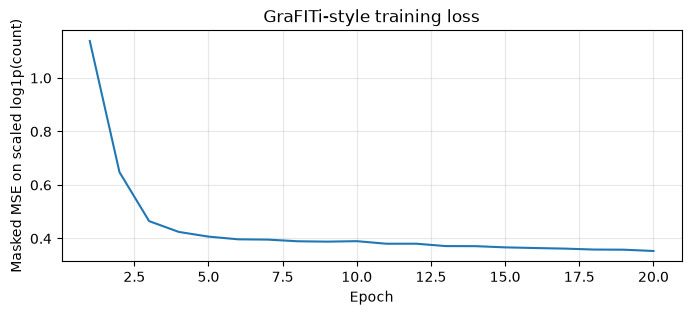

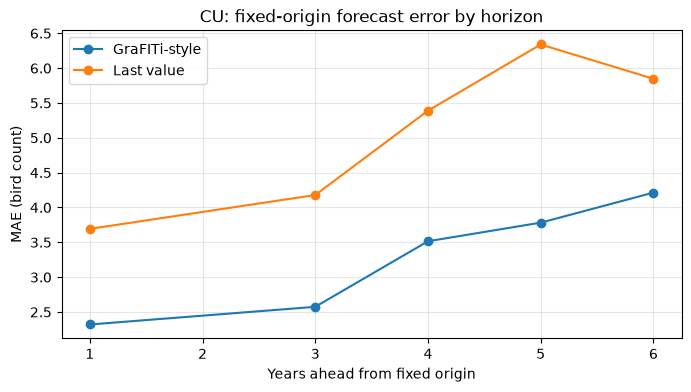

In [16]:
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(range(1, len(grafiti.history_) + 1), grafiti.history_)
ax.set(xlabel="Epoch", ylabel="Masked MSE on scaled log1p(count)", title="GraFITi-style training loss")
ax.grid(alpha=0.3)
plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
for label, report in [("GraFITi-style", grafiti_report), ("Last value", naive_report)]:
    error = (report.predictions.assign(horizon=lambda df: df.year - FORECAST_ORIGIN)
             .groupby("horizon")["absolute_error"].mean())
    ax.plot(error.index, error.values, marker="o", label=label)
ax.set(xlabel="Years ahead from fixed origin", ylabel="MAE (bird count)",
       title=f"{SPECIES}: fixed-origin forecast error by horizon")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

## 5 · Example square: forecast versus observations

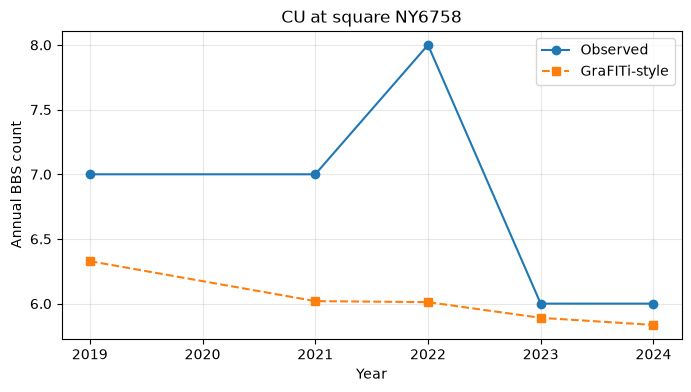

In [ ]:
SQUARE = str(test.OS_GRID_REF.iloc[0])
subset = grafiti_report.predictions.loc[grafiti_report.predictions.OS_GRID_REF.eq(SQUARE)]
subset = subset.sort_values("year")
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(subset.year, subset[task.target], "o-", label="Observed")
ax.plot(subset.year, subset.prediction, "s--", label="GraFITi-style")
ax.set(xlabel="Year", ylabel="Annual BBS count", title=f"{SPECIES} at square {SQUARE}")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

## 6 · Save predictions (compatible with your plots notebook)

When enabled, saves a per-species CSV in the existing hashed model directory. The saved manifest includes all hyperparameters and the fixed-origin settings. **Set `DATASET_RELEASE`** before storing results to distinguish data revisions.

In [18]:
if SAVE_PREDICTIONS:
    folder = save_forecast_results(
        grafiti_report,
        output_root=PROJECT_ROOT / "data" / "predictions",
        model_name="grafiti-style",
        task=task,
        model_params=asdict(CONFIG),
        run_config={
            "species": SPECIES,
            "dataset_release": DATASET_RELEASE,
            "forecast_origin": FORECAST_ORIGIN,
            "test_end": TEST_END_YEAR,
            "max_sites": MAX_SITES,
            "context": "observed training years only",
            "forecasting": "direct multi-horizon, fixed origin",
            "implementation": "independent sparsity-graph adaptation, not official GraFITi",
        },
    )
    print(f"Predictions saved: {folder}")
else:
    print("Set SAVE_PREDICTIONS=True to save for 03_plot_predictions.ipynb")

Predictions saved: /mnt/bulk/ukbbs-workflow/data/predictions/grafiti-style__14b9baf11c5c
